In [2]:
import os
import typing
from sklearn.gaussian_process.kernels import *
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
import matplotlib.pyplot as plt
from matplotlib import cm
from tqdm import tqdm


# Set `EXTENDED_EVALUATION` to `True` in order to visualize your predictions.
EXTENDED_EVALUATION = False
EVALUATION_GRID_POINTS = 300  # Number of grid points used in extended evaluation

# Cost function constants
COST_W_UNDERPREDICT = 50.0
COST_W_NORMAL = 1.0


# Model

In [32]:
class Model(object):
    """
    Model for this task.
    You need to implement the fit_model and predict_pollution methods
    without changing their signatures, but are allowed to create additional methods.
    """

    def __init__(self):
        """
        Initialize your model here.
        We already provide a random number generator for reproducibility.
        """
        self.rng = np.random.default_rng(seed=0)
        # Initialize kernel as RBF
        self.kernel = RBF(length_scale=5e-4, length_scale_bounds=(1e-5,1e-2))

        # Define number of processes
        self.n_processes = 64 # Must be a square number
        self.n_window  = 0.15 
        self.stride = (1 - self.n_window) / (np.sqrt(self.n_processes) - 1)
        self.GPs = [] 
        for i in range(self.n_processes):
            GPi = GaussianProcessRegressor(kernel=self.kernel, n_restarts_optimizer=9)
            self.GPs.append(GPi)

    """
    def classify_zones(self, n_window, stride, coordinates):
        ''' 
        Defines a zoning of the city with n different zones. n_window and stride must be chosen such that. 
        n_window + k * stride equals to 1 for some k. 
        Coordinates is a 2d array (N, 2) that contains the relative coordinates of each point

        returns a new array of shape (N, 2, n), where the last coordinate is a list of n binary numbers, 
        indicating whether the coordinate is in a given location or not. 
        '''

        # Compute number of cells. Make sure that it is an integer
        print('n_window', n_window)
        print('stride', stride)
        k = (1 - n_window) / stride 
        N_regions = int(k**2)
        
        N = coordinates.shape[0]
        ext_coords = {}
        char_funcs = np.zeros((N, N_regions))


        ## BETTER: Have k**2 lists and fill coordinates. This is going to be training data for each local GP

        for n in range(len(coordinates[0])):
            # Array for storing indices
            idxs = np.zeros(N_regions)
            coord = coordinates[n]
            x = coord[0]
            y = coord[1]


            # Iterate over windows
            for i in range(int(k)):
                vertical_bounds = [n_window * i, n_window * (i + 1)]

                # Check if vertical direction is contained in the bounds
                if y >= vertical_bounds[0] and y < vertical_bounds[1]:  

                    # Iterate over horizontal windows
                    for j in range(int(k)):
                        horizontal_bounds = [n_window * j, n_window * (j + 1)]

                        # If the horizontal coordinate is within bounds, correct the index
                        if x >= horizontal_bounds[0] and x < horizontal_bounds[1]:
                            idxs[i + j] = 1
            
            char_funcs[i,:] = idxs
            

        return char_funcs 

    """
    
    def classify_zones(self, n_window, stride, coordinates):
        """
        Overlapping square windows of side n_window, shifted by stride, on [0,1]^2.
        Requires n_window + k*stride == 1 for some integer k.
        Returns (N, (k+1)**2) binary array; entry [n, i*(k+1)+j] = 1 if point n
        lies in window (row i along y, column j along x).
        """
        k_float = (1 - n_window) / stride
        k = int(round(k_float))
        if not np.isclose(k, k_float):
            raise ValueError("n_window + k*stride must equal 1 for integer k")
        n_per_axis = k + 1

        starts = np.arange(n_per_axis) * stride            # (n_per_axis,)
        x = coordinates[:, 0][:, None]                     # (N, 1)
        y = coordinates[:, 1][:, None]

        in_x = (x >= starts) & (x < starts + n_window)     # (N, n_per_axis)
        in_y = (y >= starts) & (y < starts + n_window)
        # include the right/top edge in the last window
        in_x[:, -1] |= np.isclose(x[:, 0], 1.0)
        in_y[:, -1] |= np.isclose(y[:, 0], 1.0)

        N = coordinates.shape[0]
        return (in_y[:, :, None] & in_x[:, None, :]).reshape(N, -1).astype(float)

    # Don't change the name or the signature of this function
    def fit_model(self, train_coordinates: np.ndarray, train_pollution_targets: np.ndarray, train_residential_flags: np.ndarray):
        """
        Fit your model on the given training data.
        :param train_coordinates: Training features as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param train_pollution_targets: Training pollution concentrations as a 1d NumPy float array of shape (NUM_SAMPLES,)
        :param train_residential_flags: Binary variable denoting whether the 2D training point is in the residential area (1) or not (0)
        """
        n_window = self.n_window 
        stride = self.stride
        char_funcs = self.classify_zones(n_window, stride, train_coordinates)
        bezirke_training = []
        bezirke_targets = []

        # DATA PREPROCESSING
        print('DATA PREPROCESSING')
        for i in tqdm(range(self.n_processes)):
            # Find training data for this neighborhood 
            bezirk_i_training = []
            bezirk_i_targets = []
            for k in range(train_coordinates.shape[0]):
                if char_funcs[k, i] == 1 :
                    bezirk_i_training.append(train_coordinates[k]) 
                    bezirk_i_targets.append(train_pollution_targets[k]) 

            # Cast to Numpy arrays
            bezirk_i_training = np.array(bezirk_i_training)
            bezirke_training.append(bezirk_i_training)
            bezirk_i_targets = np.array(bezirk_i_targets)
            bezirke_targets.append(bezirk_i_targets)

        # FITTING LOOP
        print('FITTING LOOP')
        for i in tqdm(range(self.n_processes)):
            # Find corresponding GP for this Bezirk
            GPi = self.GPs[i]
            training_coords_i = bezirke_training[i]
            training_targets_i = bezirke_targets[i]
            print('shape coords', training_coords_i.shape)  
            self.GPs[i] = GPi.fit(training_coords_i, training_targets_i)


        pass

    # Don't change the name or the signature of this function
    def predict_pollution(self, test_coordinates: np.ndarray, test_residential_flags: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """
        Predict the pollution concentration for a given set of city_areas.
        :param test_coordinates: city_areas as a 2d NumPy float array of shape (NUM_SAMPLES, 2)
        :param test_residential_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
        :return:
            Tuple of three 1d NumPy float arrays, each of shape (NUM_SAMPLES,),
            containing your predictions, the GP posterior mean, and the GP posterior stddev (in that order)
        """

        # TODO: Use your GP to estimate the posterior mean and stddev for each city_area here
        gp_mean = np.zeros(test_coordinates.shape[0], dtype=float)
        gp_std = np.zeros(test_coordinates.shape[0], dtype=float)

        # Extract characteristic functions (NUM_SAMPLES, n_zones)
        char_funcs = self.classify_zones(self.n_window, self.stride, test_coordinates)
        GP_means = [] 
        GP_stds = [] 
        for i in range(self.n_processes):
            GPi_means, GPi_stds = self.GPs[i].predict(test_coordinates, return_std=True)
            GP_means.append(GPi_means)
            GP_stds.append(GPi_stds)

        GP_means = np.array(GP_means) # (NUM_SAMPLES, n_processes)
        GP_stds = np.array(GP_stds)

        tot_zones = np.sum(char_funcs, axis=1) # (NUM_SAMPLES,) How many areas does a given point belong to

        GP_means_relevant = np.sum(GP_means.T * char_funcs, axis=1) / tot_zones


        # TODO: Use the GP posterior to form your predictions here
        predictions = GP_means_relevant 

        return predictions, gp_mean, gp_std


# Cost and Helper functions

In [23]:
# You don't have to change this function
def calculate_cost(ground_truth: np.ndarray, predictions: np.ndarray, residential_flags: np.ndarray) -> float:
    """
    Calculates the cost of a set of predictions.

    :param ground_truth: Ground truth pollution levels as a 1d NumPy float array
    :param predictions: Predicted pollution levels as a 1d NumPy float array
    :param residential_flags: city_area info for every sample in a form of a bool array (NUM_SAMPLES,)
    :return: Total cost of all predictions as a single float
    """
    assert ground_truth.ndim == 1 and predictions.ndim == 1 and ground_truth.shape == predictions.shape

    # Unweighted cost
    cost = (ground_truth - predictions) ** 2
    weights = np.ones_like(cost) * COST_W_NORMAL

    # Case i): underprediction
    mask = (predictions < ground_truth) & [bool(residential_flag) for residential_flag in residential_flags]
    weights[mask] = COST_W_UNDERPREDICT

    # Weigh the cost and return the average
    return np.mean(cost * weights)


# You don't have to change this function
def is_inside_circle(coordinate, circle_parameters):
    """
    Checks if a coordinate is inside a circle.
    :param coordinate: 2D coordinate
    :param circle_parameters: 3D coordinate of the circle center and its radius
    :return: True if the coordinate is inside the circle, False otherwise
    """
    return (coordinate[0] - circle_parameters[0])**2 + (coordinate[1] - circle_parameters[1])**2 < circle_parameters[2]**2

# You don't have to change this function
def determine_residential_flags(grid_coordinates):
    """
    Determines the city_area index for each coordinate in the visualization grid.
    :param grid_coordinates: 2D coordinates of the visualization grid
    :return: 1D array of city_area indexes
    """
    # Circles coordinates
    circles = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])

    residential_flags = np.zeros((grid_coordinates.shape[0],))

    for i,coordinate in enumerate(grid_coordinates):
        residential_flags[i] = any([is_inside_circle(coordinate, circ) for circ in circles])

    return residential_flags


# Don't change the name or the signature of this function
def perform_extended_model_evaluation(model: Model, output_dir: str = '/results'):
    """
    Visualizes the predictions of a fitted model.
    :param model: Fitted model to be visualized
    :param output_dir: Directory in which the visualizations will be stored
    """
    print('Performing extended evaluation')

    # Visualize on a uniform grid over the entire coordinate system
    grid_lat, grid_lon = np.meshgrid(
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
        np.linspace(0, EVALUATION_GRID_POINTS - 1, num=EVALUATION_GRID_POINTS) / EVALUATION_GRID_POINTS,
    )
    visualization_grid = np.stack((grid_lon.flatten(), grid_lat.flatten()), axis=1)
    grid_residential_flags = determine_residential_flags(visualization_grid)

    # Obtain predictions, means, and stddevs over the entire map
    predictions, gp_mean, gp_stddev = model.predict_pollution(visualization_grid, grid_residential_flags)
    predictions = np.reshape(predictions, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))
    gp_mean = np.reshape(gp_mean, (EVALUATION_GRID_POINTS, EVALUATION_GRID_POINTS))

    vmin, vmax = 0.0, 65.0

    # Plot the actual predictions
    fig, ax = plt.subplots()
    ax.set_title('Extended visualization of task 1')
    im = ax.imshow(predictions, vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax)

    # Save figure to pdf
    figure_path = os.path.join(output_dir, 'extended_evaluation.pdf')
    fig.savefig(figure_path)
    print(f'Saved extended evaluation to {figure_path}')

    plt.show()

# You do not need to change the name or the signature of this function; convenience helper used by main() 
def get_city_area_data(train_x: np.ndarray, test_x: np.ndarray) -> typing.Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Extracts the city_area information from the training and test features.
    :param train_x: Training features
    :param test_x: Test features
    :return: Tuple of (training features' 2D coordinates, training features' city_area information,
        test features' 2D coordinates, test features' city_area information)
    """
    train_coordinates = np.zeros((train_x.shape[0], 2), dtype=float)
    train_residential_flags = np.zeros((train_x.shape[0],), dtype=bool)
    test_coordinates = np.zeros((test_x.shape[0], 2), dtype=float)
    test_residential_flags = np.zeros((test_x.shape[0],), dtype=bool)

    train_residential_flags = train_x[:,2]
    test_residential_flags = test_x[:,2]

    train_coordinates = train_x[:,:2]
    test_coordinates = test_x[:,:2]

    test_residential_flags_2 = determine_residential_flags(test_coordinates)
    train_residential_flags_2 = determine_residential_flags(train_coordinates)

    for i in range(len(train_residential_flags)):

        assert train_residential_flags[i] == train_residential_flags_2[i]
        if i < len(test_residential_flags):
            assert test_residential_flags[i] == test_residential_flags_2[i]

    assert train_coordinates.shape[0] == train_residential_flags.shape[0] and test_coordinates.shape[0] == test_residential_flags.shape[0]
    assert train_coordinates.shape[1] == 2 and test_coordinates.shape[1] == 2
    assert train_residential_flags.ndim == 1 and test_residential_flags.ndim == 1

    return train_coordinates, train_residential_flags, test_coordinates, test_residential_flags

# you don't have to change this function


# Visualize Measurements and Residential Areas

(15189, 2)
(15189,)


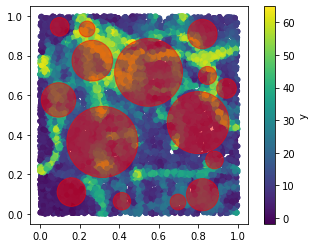

0

In [5]:
def visualize_measurements():

    # Load the training dataset and test features
    train_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
    train_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
    test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)


    # Extract the city_area information
    train_coordinates, train_residential_flags, test_coordinates, test_residential_flags = get_city_area_data(train_x, test_x)
    print(train_coordinates.shape)
    print(train_residential_flags.shape)

       # Plot the actual predictions
    fig, ax = plt.subplots()
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    CIRCLES = np.array([[0.5488135, 0.71518937, 0.17167342],
                    [0.79915856, 0.46147936, 0.1567626 ],
                    [0.26455561, 0.77423369, 0.10298338],
                    [0.6976312,  0.06022547, 0.04015634],
                    [0.31542835, 0.36371077, 0.17985623],
                    [0.15896958, 0.11037514, 0.07244247],
                    [0.82099323, 0.09710128, 0.08136552],
                    [0.41426299, 0.0641475,  0.04442035],
                    [0.09394051, 0.5759465,  0.08729856],
                    [0.84640867, 0.69947928, 0.04568374],
                    [0.23789282, 0.934214,   0.04039037],
                    [0.82076712, 0.90884372, 0.07434012],
                    [0.09961493, 0.94530153, 0.04755969],
                    [0.88172021, 0.2724369,  0.04483477],
                    [0.9425836,  0.6339977,  0.04979664]])

    from matplotlib.patches import Circle

    for cx, cy, r in CIRCLES:
        ax.add_patch(Circle((cx, cy), r, facecolor="red", alpha=0.5,
                        edgecolor="red", linewidth=1, zorder=2))
    map = ax.scatter(train_coordinates[:, 0], train_coordinates[:, 1], c=train_y, cmap="viridis", s=20)
    fig.colorbar(map, ax=ax, label="y")
    #test = ax.scatter(test_coordinates[:,0], test_coordinates[:,1])
    ax.set_aspect("equal")
    plt.show()
   
    # train_coordinates is an array of shape (n_train, 2). We want do place 
    return 0 

visualize_measurements()


Having such a map, we may continue implementing the GP. 

In [33]:
    # Load the training dataset and test features
train_x = np.loadtxt('train_x.csv', delimiter=',', skiprows=1)
train_y = np.loadtxt('train_y.csv', delimiter=',', skiprows=1)
test_x = np.loadtxt('test_x.csv', delimiter=',', skiprows=1)

# Extract the city_area information
train_coordinates, train_residential_flags, test_coordinates, test_residential_flags = get_city_area_data(train_x, test_x)

    # Fit the model
print('Training model')
model = Model()
model.fit_model(train_coordinates, train_y, train_residential_flags)

    # Predict on the test features
print('Predicting on test features')
predictions = model.predict_pollution(test_coordinates, test_residential_flags)
print(predictions)

Training model
DATA PREPROCESSING


100%|██████████| 64/64 [00:00<00:00, 198.58it/s]


FITTING LOOP


  0%|          | 0/64 [00:00<?, ?it/s]

shape coords (297, 2)


  3%|▎         | 2/64 [00:00<00:13,  4.64it/s]

... (95 outputs left out)

 97%|█████████▋| 62/64 [00:35<00:01,  1.22it/s]

shape coords (371, 2)


100%|██████████| 64/64 [00:36<00:00,  1.76it/s]


shape coords (181, 2)
Predicting on test features
(array([28.4110031 , 58.70816129, 59.40063734, ..., 31.36647649,
       48.42283289, 57.26969894]), array([0., 0., 0., ..., 0., 0., 0.]), array([0., 0., 0., ..., 0., 0., 0.]))


[28.4110031  58.70816129 59.40063734 ... 31.36647649 48.42283289
 57.26969894]
Performing extended evaluation
Saved extended evaluation to ./extended_evaluation.pdf


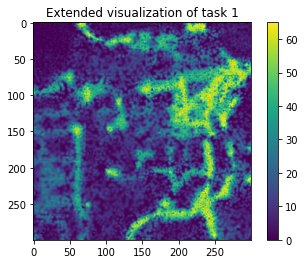

In [34]:
print(predictions[0])

EXTENDED_EVALUATION = True
if EXTENDED_EVALUATION:
    perform_extended_model_evaluation(model, output_dir='.')